## Volume Curves

In [1]:
from datetime import date

from cdxcore.util import fmt_date

from quantdata import Context, env
from quantdata.volume_curves.curve_bins import _TOP_TRADED_ETFS, ticker_curve_bins

start = date(2015, 1, 1)
end = date(2026, 1, 1)
bucket_minutes = 15
tickers = _TOP_TRADED_ETFS  # or e.g. ['SPY', 'TLT'] for a subset
tickers = ["SPY", "TLT"]

for ticker in tickers:
    ticker_curve_bins(ticker, start, end, bucket_minutes=bucket_minutes, verbose=Context.all)

curve_root = env.locations.processing("volume_curves")(
    f"{fmt_date(start)} {fmt_date(end)}@{bucket_minutes}"
)

In [2]:
%matplotlib inline
from __future__ import annotations

from datetime import date, timedelta

import numpy as np
import polars as pl
from cdxcore.dynaplot import colors_tableau, figure
from cdxcore.pretty import PrettyObject
from cdxcore.util import fmt_big_byte_number, fmt_date, fmt_list
from IPython.display import Markdown, display

from quantdata.volume_curves.load_bins import (
    Context,
    load_curve_definition,
    load_curve_files,
    merge_curve_files,
)

curve_def = load_curve_definition(curve_root, verbose=Context.all)
print(curve_def["files"])
df_daily = merge_curve_files(
    curve_root,
    tickers=["SPY", "TLT"],  # curve_def["files"], ['TLT'], # <-- use individual tickers if need be
    start=curve_def["start"],
    end=curve_def["end"],
    bucket_minutes=curve_def["bucket_minutes"],
    verbose=Context.all,
)

# compute normalized close
df_daily = df_daily.sort(["ticker", "date"]).with_columns(
    pl.col("return_daily").cum_sum().over("ticker").exp().alias("daily_normalized_close")
)
df_daily = df_daily.filter(~pl.col("is_half_day")).drop("is_half_day")


display(df_daily.head())
display(df_daily.tail())
print(df_daily.columns)

['EEM', 'curve_def', 'XLU', 'XLB', 'XLV', 'LQD', 'GLD', 'VTI', 'IVV', 'QQQ', 'XLE', 'XLP', 'XLF', 'SPY', 'XLK', 'DIA', 'XLI', 'IWM', 'VOO', 'XLY', 'TLT', 'FXI', 'SLV', 'HYG']
00: Loaded 2 files from /Users/jonathanplenk/Python Projects/Finance/quant_data/data_folder/processing/volume_curves/2015-01-01 2026-01-01@15/;*.pck; this took 0.019s.
00: Filling half-day trailing bucket nulls with 0... done (48 cols); this took 0.015s.
00: Checking bucket columns for nulls... ok; this took 3.44ms.


date,cash_vol_daily,vol_daily,n_trades_daily,return_daily,vol_overnight,vol_bucket_00,cash_vol_bucket_00,n_trades_bucket_00,return_bucket_00,vol_bucket_01,cash_vol_bucket_01,n_trades_bucket_01,return_bucket_01,vol_bucket_02,cash_vol_bucket_02,n_trades_bucket_02,return_bucket_02,vol_bucket_03,cash_vol_bucket_03,n_trades_bucket_03,return_bucket_03,vol_bucket_04,cash_vol_bucket_04,n_trades_bucket_04,return_bucket_04,vol_bucket_05,cash_vol_bucket_05,n_trades_bucket_05,return_bucket_05,vol_bucket_06,cash_vol_bucket_06,n_trades_bucket_06,return_bucket_06,vol_bucket_07,cash_vol_bucket_07,n_trades_bucket_07,…,n_trades_bucket_18,return_bucket_18,vol_bucket_19,cash_vol_bucket_19,n_trades_bucket_19,return_bucket_19,vol_bucket_20,cash_vol_bucket_20,n_trades_bucket_20,return_bucket_20,vol_bucket_21,cash_vol_bucket_21,n_trades_bucket_21,return_bucket_21,vol_bucket_22,cash_vol_bucket_22,n_trades_bucket_22,return_bucket_22,vol_bucket_23,cash_vol_bucket_23,n_trades_bucket_23,return_bucket_23,vol_bucket_24,cash_vol_bucket_24,n_trades_bucket_24,return_bucket_24,vol_bucket_25,cash_vol_bucket_25,n_trades_bucket_25,return_bucket_25,is_ex_div,is_split,has_ticker_change,is_earnings,has_expiry,ticker,daily_normalized_close
date,f32,f32,i32,f64,f32,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,…,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,bool,bool,bool,bool,i8,str,f64
2014-12-31,10.32742,0.093106,341054,-0.010069,0.02903,0.082174,10.419778,17989,-0.001203,0.042583,10.041538,8168,0.000289,0.079097,9.935183,6786,0.000501,0.044754,10.224413,7089,0.000173,0.030178,9.979953,6289,0.000433,0.038748,10.112983,7602,0.000369,0.043774,10.246188,6270,-0.00085,0.044718,10.213745,7383,…,11498,-0.001401,0.122935,10.483367,19828,-0.001209,0.114542,10.371783,15776,-0.001114,0.06586,10.397689,12436,-0.000242,0.092467,10.275861,14511,0.00046,0.076585,10.44033,15773,0.000775,0.112224,10.58221,24201,-0.002156,0.207377,11.053926,61581,-0.002964,false,false,false,false,4,"""SPY""",0.989981
2015-01-02,10.328564,0.137323,371608,-0.000584,0.065516,0.123571,10.576363,26697,0.001694,0.102228,10.527774,18701,-0.001065,0.203226,10.547539,24915,-0.000872,0.126445,10.349048,13950,-0.001358,0.156634,10.668826,29572,-0.005255,0.123706,10.393363,16422,0.001268,0.155722,10.461328,20227,-0.002684,0.124401,10.344046,15984,…,10985,0.001538,0.116728,10.223584,8410,0.000146,0.106514,10.040616,8423,0.001073,0.103097,10.212939,10102,-0.000507,0.128143,10.220497,11939,-0.001396,0.124339,10.115865,9856,0.001805,0.093409,10.399179,18600,0.001608,0.155846,10.670746,33216,-0.000292,false,false,false,false,null,"""SPY""",0.989403
2015-01-05,10.483065,0.165072,499557,-0.017731,0.096121,0.185159,10.691735,38307,-0.000931,0.165293,10.545774,28590,-0.00422,0.136035,10.534851,24630,0.000586,0.135072,10.367599,17151,3.8242e-8,0.146013,10.632058,26479,-0.003302,0.138726,10.546726,17408,0.001135,0.115772,10.501116,18824,-0.001031,0.140591,10.544247,21132,…,14761,-0.001645,0.133509,10.315279,15953,0.000332,0.135586,10.295145,16636,-0.001488,0.103098,10.352871,15304,0.00005,0.139629,10.431754,17499,0.001884,0.114624,10.420715,15692,-0.000347,0.176114,10.589149,23576,0.000941,0.153478,10.949811,51439,-0.000693,false,false,false,false,null,"""SPY""",0.972015
2015-01-06,10.578975,0.164486,636049,-0.00986,0.022796,0.175003,10.656317,32190,-0.000842,0.154813,10.431731,19188,0.00059,0.255774,10.7061,32399,0.001686,0.102886,10.59281,23848,0.00084,0.140795,10.417444,18394,-0.00371,0.130847,10.530905,24388,-0.00253,0.162003,10.548729,26739,-0.000646,0.121006,10.625817,24524,…,17841,-0.002851,0.140566,10.538828,16992,0.003856,0.158874,10.721496,26804,0.002845,0.147762,10.567065,25031,-0.00006,0.173347,10.514555,22476,0.000458,0.237368,10.5622,26354,0.002836,0.219174,10.535521,25945,-0.002587,0.192263,10.912625,48340,-0.004693,false,false,false,false,null,"""SPY""",0.9

date,cash_vol_daily,vol_daily,n_trades_daily,return_daily,vol_overnight,vol_bucket_00,cash_vol_bucket_00,n_trades_bucket_00,return_bucket_00,vol_bucket_01,cash_vol_bucket_01,n_trades_bucket_01,return_bucket_01,vol_bucket_02,cash_vol_bucket_02,n_trades_bucket_02,return_bucket_02,vol_bucket_03,cash_vol_bucket_03,n_trades_bucket_03,return_bucket_03,vol_bucket_04,cash_vol_bucket_04,n_trades_bucket_04,return_bucket_04,vol_bucket_05,cash_vol_bucket_05,n_trades_bucket_05,return_bucket_05,vol_bucket_06,cash_vol_bucket_06,n_trades_bucket_06,return_bucket_06,vol_bucket_07,cash_vol_bucket_07,n_trades_bucket_07,…,n_trades_bucket_18,return_bucket_18,vol_bucket_19,cash_vol_bucket_19,n_trades_bucket_19,return_bucket_19,vol_bucket_20,cash_vol_bucket_20,n_trades_bucket_20,return_bucket_20,vol_bucket_21,cash_vol_bucket_21,n_trades_bucket_21,return_bucket_21,vol_bucket_22,cash_vol_bucket_22,n_trades_bucket_22,return_bucket_22,vol_bucket_23,cash_vol_bucket_23,n_trades_bucket_23,return_bucket_23,vol_bucket_24,cash_vol_bucket_24,n_trades_bucket_24,return_bucket_24,vol_bucket_25,cash_vol_bucket_25,n_trades_bucket_25,return_bucket_25,is_ex_div,is_split,has_ticker_change,is_earnings,has_expiry,ticker,daily_normalized_close
date,f32,f32,i32,f64,f32,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,…,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,f32,f32,i32,f64,bool,bool,bool,bool,i8,str,f64
2025-12-23,9.325488,0.065507,77398,0.00183,0.050059,0.059976,9.649559,7132,-0.000238,0.048376,9.386114,4171,0.000238,0.061295,9.540267,5992,0.001664,0.051051,9.393058,3756,0.000745,0.068151,9.272582,3585,0.000687,0.047548,9.749572,5459,0.000115,0.035256,9.389963,3484,0.000461,0.049521,9.143698,2866,…,1738,-0.000781,0.022582,8.908313,1703,0.000152,0.024047,8.876116,843,-0.000286,0.042303,8.955229,1269,0.000644,0.028581,8.944446,1596,0.000157,0.021698,8.972062,1410,0.000114,0.02855,9.33128,2089,0.000457,0.039751,9.842821,9889,-0.000343,false,false,false,false,null,"""TLT""",0.697918
2025-12-26,9.261686,0.052581,76056,-0.003186,0.014422,0.050069,9.345476,5190,0.00034,0.063291,9.211132,3880,-0.000482,0.046922,9.106558,2855,-0.000028,0.058487,9.217059,4214,-0.001022,0.023857,9.242977,3179,-1.0305e-7,0.056604,9.276977,3054,0.000284,0.115461,9.430401,4033,-0.00182,0.113021,9.726216,6441,…,1353,0.000114,0.027141,8.794572,957,-0.000114,0.031698,8.866163,1263,-0.000057,0.051661,9.210211,1901,0.000684,0.029172,8.899781,1908,0.000286,0.025288,8.826911,2106,-0.000115,0.029704,8.965477,1934,-0.000057,0.035835,9.729393,7607,0.000285,false,false,false,false,null,"""TLT""",0.699793
2025-12-29,9.293612,0.058057,73168,0.003413,0.037949,0.064179,9.538316,6379,0.000852,0.052572,9.445886,4534,-0.000739,0.102212,9.494941,4805,-0.000398,0.03573,9.315519,3497,-0.000562,0.066463,9.407262,4749,-0.000064,0.042365,9.214601,3295,-1.7753e-8,0.055916,9.222836,3218,0.000341,0.038989,8.867662,2698,…,1120,-0.00017,0.018988,8.936739,1114,0.000002,0.031668,9.31559,1903,-0.000116,0.04719,9.29282,1975,0.000057,0.033557,8.976572,1939,0.000341,0.025187,9.307774,1284,-0.000284,0.032178,9.504542,1516,0.000346,0.035224,9.702864,7855,0.000734,false,false,false,false,null,"""TLT""",0.702185
2025-12-30,9.28217,0.071485,64841,-0.001819,0.054186,0.052604,9.290609,4064,-0.000252,0.056437,9.440025,5499,-0.000033,0.045923,9.261154,3304,0.000171,0.042724,9.309045,4601,0.000228,0.096065,9.419915,3692,-0.000114,0.059941,9.183884,2767,0.000729,0.052438,9.290883,3086,0.000808,0.08318,9.479483,4201,…,875,0.000398,0.025164,8.705791,750,-0.000119,0.031468,8.717031,819,-0.000166,0.05994,9.396163,2587,-0.000795,0.021864,8.982463,1079,-0.000114,0.026086,9.134837,2624,0.000228,0.026653,9.657162,1240,0.000171,0.038238,9.779869,7600,0.00017,false,false,false,false,null,"""TLT""",0.700909
2025-12-31,9.430341,0.067924,101766,-0.008112,0.036168,0.065028,9.365299,3954,0.001482,0.085105,9.201301,4012,0.000

['date', 'cash_vol_daily', 'vol_daily', 'n_trades_daily', 'return_daily', 'vol_overnight', 'vol_bucket_00', 'cash_vol_bucket_00', 'n_trades_bucket_00', 'return_bucket_00', 'vol_bucket_01', 'cash_vol_bucket_01', 'n_trades_bucket_01', 'return_bucket_01', 'vol_bucket_02', 'cash_vol_bucket_02', 'n_trades_bucket_02', 'return_bucket_02', 'vol_bucket_03', 'cash_vol_bucket_03', 'n_trades_bucket_03', 'return_bucket_03', 'vol_bucket_04', 'cash_vol_bucket_04', 'n_trades_bucket_04', 'return_bucket_04', 'vol_bucket_05', 'cash_vol_bucket_05', 'n_trades_bucket_05', 'return_bucket_05', 'vol_bucket_06', 'cash_vol_bucket_06', 'n_trades_bucket_06', 'return_bucket_06', 'vol_bucket_07', 'cash_vol_bucket_07', 'n_trades_bucket_07', 'return_bucket_07', 'vol_bucket_08', 'cash_vol_bucket_08', 'n_trades_bucket_08', 'return_bucket_08', 'vol_bucket_09', 'cash_vol_bucket_09', 'n_trades_bucket_09', 'return_bucket_09', 'vol_bucket_10', 'cash_vol_bucket_10', 'n_trades_bucket_10', 'return_bucket_10', 'vol_bucket_11', '

## Close

### Daily (normalized) Close and Log-Volume

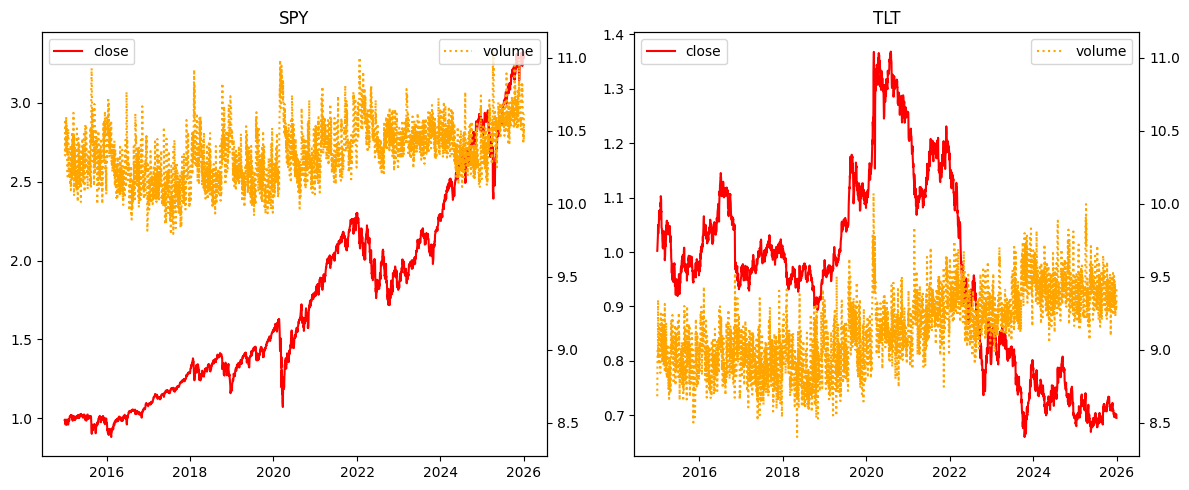

### Daily Annualized Vol

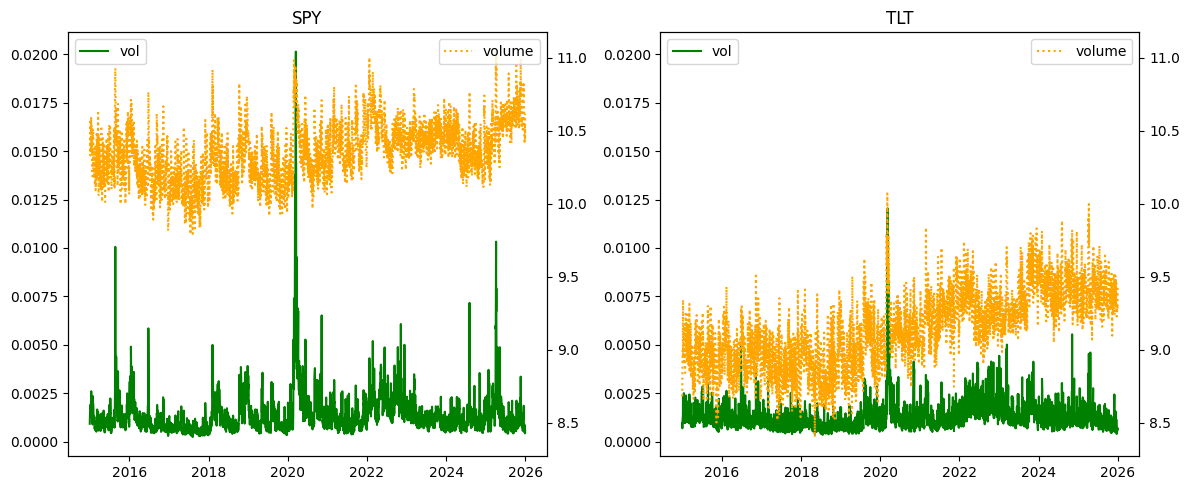

In [3]:
def plot_all(df_daily):
    tickers = sorted(df_daily["ticker"].unique())

    display(Markdown("### Daily (normalized) Close and Log-Volume"))
    with figure(col_size=6, row_size=5, columns=4) as fig:
        prev_ax = None
        prev_ax2 = None
        for ticker in tickers:
            daily = (
                df_daily.filter(pl.col("ticker") == ticker)
                .select(["date", "daily_normalized_close", "cash_vol_daily"])
                .sort("date")
            )
            splits = df_daily.filter((pl.col("ticker") == ticker) & pl.col("is_split"))[
                "date"
            ].to_list()
            dates = daily["date"]

            ax = fig.add_subplot(ticker)
            ax2 = ax.twinx()
            #            ax.sharey(prev_ax) if prev_ax is not None else None
            ax2.sharey(prev_ax2) if prev_ax2 is not None else None
            ax.plot(daily["date"], daily["daily_normalized_close"], "-", label="close", color="red")
            if len(splits) > 0:
                sdaily = daily.filter(pl.col("date").is_in(splits))
                ax.plot(
                    sdaily["date"],
                    sdaily["daily_normalized_close"],
                    "o",
                    label="splits",
                    color="red",
                )

            ax2.plot(daily["date"], daily["cash_vol_daily"], ":", label="volume", color="orange")
            ax.legend(loc="upper left")
            ax2.legend(loc="upper right")

            prev_ax = ax
            prev_ax2 = ax2

    display(Markdown("### Daily Annualized Vol"))
    with figure(col_size=6, row_size=5, columns=4) as fig:
        prev_ax = None
        prev_ax2 = None
        for ticker in tickers:
            daily = (
                df_daily.filter(pl.col("ticker") == ticker)
                .select(["date", "vol_daily", "cash_vol_daily"])
                .sort("date")
            )
            dates = daily["date"]

            ax = fig.add_subplot(ticker)
            ax2 = ax.twinx()
            ax.sharey(prev_ax) if prev_ax is not None else None
            ax2.sharey(prev_ax2) if prev_ax2 is not None else None
            ax.plot(daily["date"], daily["vol_daily"] / 100.0, "-", label="vol", color="green")
            ax2.plot(daily["date"], daily["cash_vol_daily"], ":", label="volume", color="orange")
            ax.legend(loc="upper left")
            ax2.legend(loc="upper right")

            prev_ax = ax
            prev_ax2 = ax2


plot_all(df_daily)

## Basic Stats (for full days only)

## SPY

---

### volume: each bucket cash_vol is scaled to daily cash volume; daily_cash_vol is the daily cash volume

,min,max,p01,p25,p50,p75,p99,mean,std
cash_vol_daily,9.793,11.04,9.945,10.2,10.34,10.49,10.82,10.35,0.1987
cash_vol_bucket_00,9.775,11.33,10.14,10.44,10.57,10.71,11.11,10.58,0.2075
cash_vol_bucket_01,9.628,11.22,9.929,10.27,10.42,10.58,11,10.43,0.2285
cash_vol_bucket_02,9.73,11.44,9.908,10.26,10.42,10.59,10.97,10.42,0.2358
cash_vol_bucket_03,9.633,11.58,9.847,10.18,10.35,10.52,10.93,10.35,0.242
cash_vol_bucket_04,9.595,11.35,9.831,10.17,10.34,10.51,10.94,10.34,0.242
cash_vol_bucket_05,9.632,11.36,9.761,10.11,10.28,10.45,10.89,10.29,0.2441
cash_vol_bucket_06,9.498,11.47,9.747,10.11,10.27,10.44,10.89,10.28,0.2481
cash_vol_bucket_07,9.417,11.32,9.703,10.07,10.24,10.41,10.81,10.24,0.2481
cash_vol_bucket_08,9.436,11.32,9.708,10.06,10.23,10.4,10.83,10.23,0.2462


### realized vol, annualized

,min,max,p01,p25,p50,p75,p99,mean,std
vol_daily,0.0247,2.013,0.03928,0.07718,0.1098,0.1637,0.5982,0.1384,0.1124
vol_overnight,0,1.846,0.0007522,0.02127,0.04607,0.08844,0.4244,0.07075,0.09371
vol_bucket_00,0.03685,1.616,0.05001,0.09356,0.1284,0.1869,0.5316,0.1576,0.1103
vol_bucket_01,0.01954,1.488,0.03755,0.07689,0.1105,0.162,0.4498,0.1343,0.09895
vol_bucket_02,0.02329,2.068,0.03554,0.07733,0.1116,0.1682,0.4984,0.1391,0.1078
vol_bucket_03,0.01767,2.072,0.03105,0.06746,0.09829,0.1481,0.4353,0.1216,0.09213
vol_bucket_04,0.01583,1.268,0.03066,0.06673,0.09662,0.1443,0.4148,0.118,0.08428
vol_bucket_05,0.01634,1.044,0.02798,0.05977,0.08776,0.1321,0.415,0.1082,0.07621
vol_bucket_06,0.01885,1.403,0.02703,0.059,0.08639,0.1301,0.4153,0.1069,0.08016
vol_bucket_07,0.01875,0.9993,0.02565,0.05471,0.07923,0.1212,0.3641,0.09959,0.07618


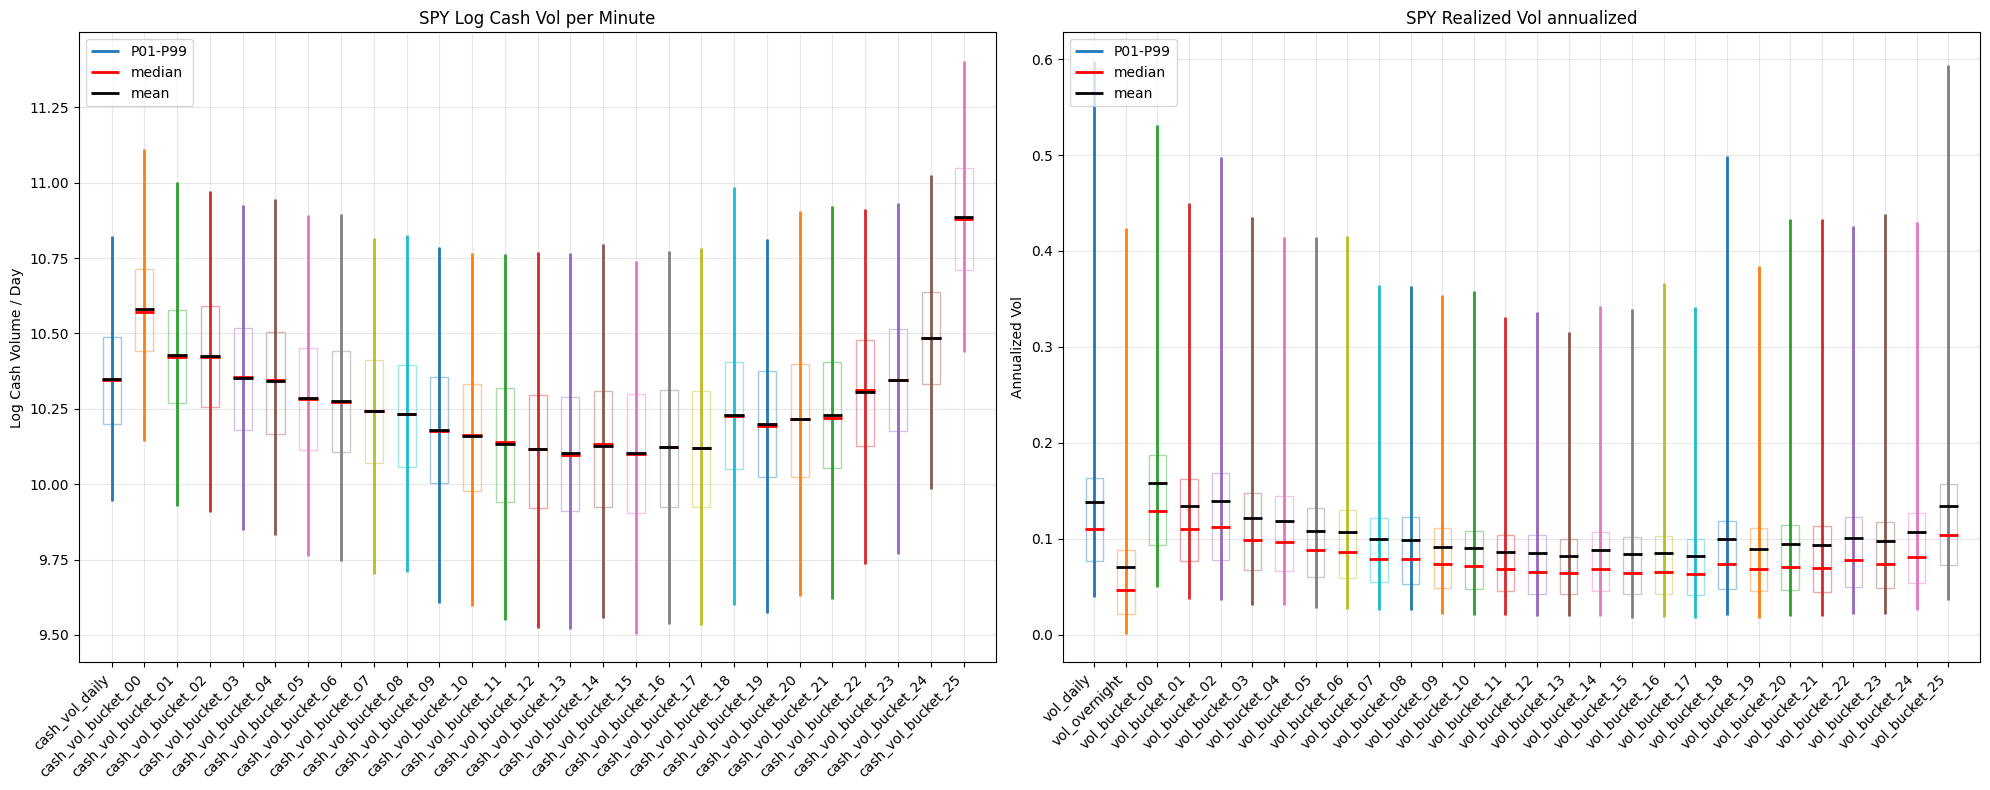

## TLT

---

### volume: each bucket cash_vol is scaled to daily cash volume; daily_cash_vol is the daily cash volume

,min,max,p01,p25,p50,p75,p99,mean,std
cash_vol_daily,8.404,10.07,8.629,8.947,9.146,9.332,9.741,9.147,0.258
cash_vol_bucket_00,8.219,10.51,8.668,9.125,9.346,9.568,10.04,9.344,0.3097
cash_vol_bucket_01,8.25,10.41,8.523,9.013,9.247,9.478,9.959,9.243,0.3214
cash_vol_bucket_02,8.125,10.41,8.509,9.014,9.25,9.481,10.01,9.244,0.3326
cash_vol_bucket_03,8.167,10.41,8.459,8.936,9.174,9.392,9.85,9.163,0.3182
cash_vol_bucket_04,7.96,10.17,8.42,8.924,9.145,9.363,9.837,9.139,0.312
cash_vol_bucket_05,8.039,10.18,8.376,8.866,9.103,9.329,9.834,9.101,0.3252
cash_vol_bucket_06,8.188,10.31,8.417,8.882,9.108,9.323,9.826,9.101,0.3152
cash_vol_bucket_07,8.072,10.46,8.33,8.821,9.054,9.292,9.848,9.057,0.3313
cash_vol_bucket_08,7.846,10.37,8.263,8.78,9.018,9.26,9.743,9.019,0.3353


### realized vol, annualized

,min,max,p01,p25,p50,p75,p99,mean,std
vol_daily,0.03538,1.204,0.04953,0.08424,0.1116,0.1522,0.3831,0.1295,0.07449
vol_overnight,0,1.133,0.001336,0.03162,0.06509,0.1102,0.3171,0.08167,0.07397
vol_bucket_00,0.0262,1.551,0.04329,0.08205,0.107,0.1408,0.3308,0.1199,0.06434
vol_bucket_01,0.01679,1.459,0.03853,0.07474,0.09798,0.1332,0.3251,0.1129,0.06566
vol_bucket_02,0.02216,0.9034,0.04087,0.0774,0.1041,0.1437,0.427,0.1233,0.07643
vol_bucket_03,0.01862,1.402,0.03641,0.07043,0.09178,0.1227,0.2972,0.1045,0.05934
vol_bucket_04,0.01847,0.7954,0.036,0.07014,0.09224,0.1225,0.2972,0.1039,0.05387
vol_bucket_05,0.02269,0.5424,0.03646,0.06648,0.08689,0.1152,0.2849,0.09714,0.04922
vol_bucket_06,0.0179,0.6736,0.03339,0.065,0.08431,0.1134,0.2694,0.09526,0.04929
vol_bucket_07,0.01393,0.6462,0.03082,0.05965,0.07794,0.1034,0.2515,0.08769,0.04689


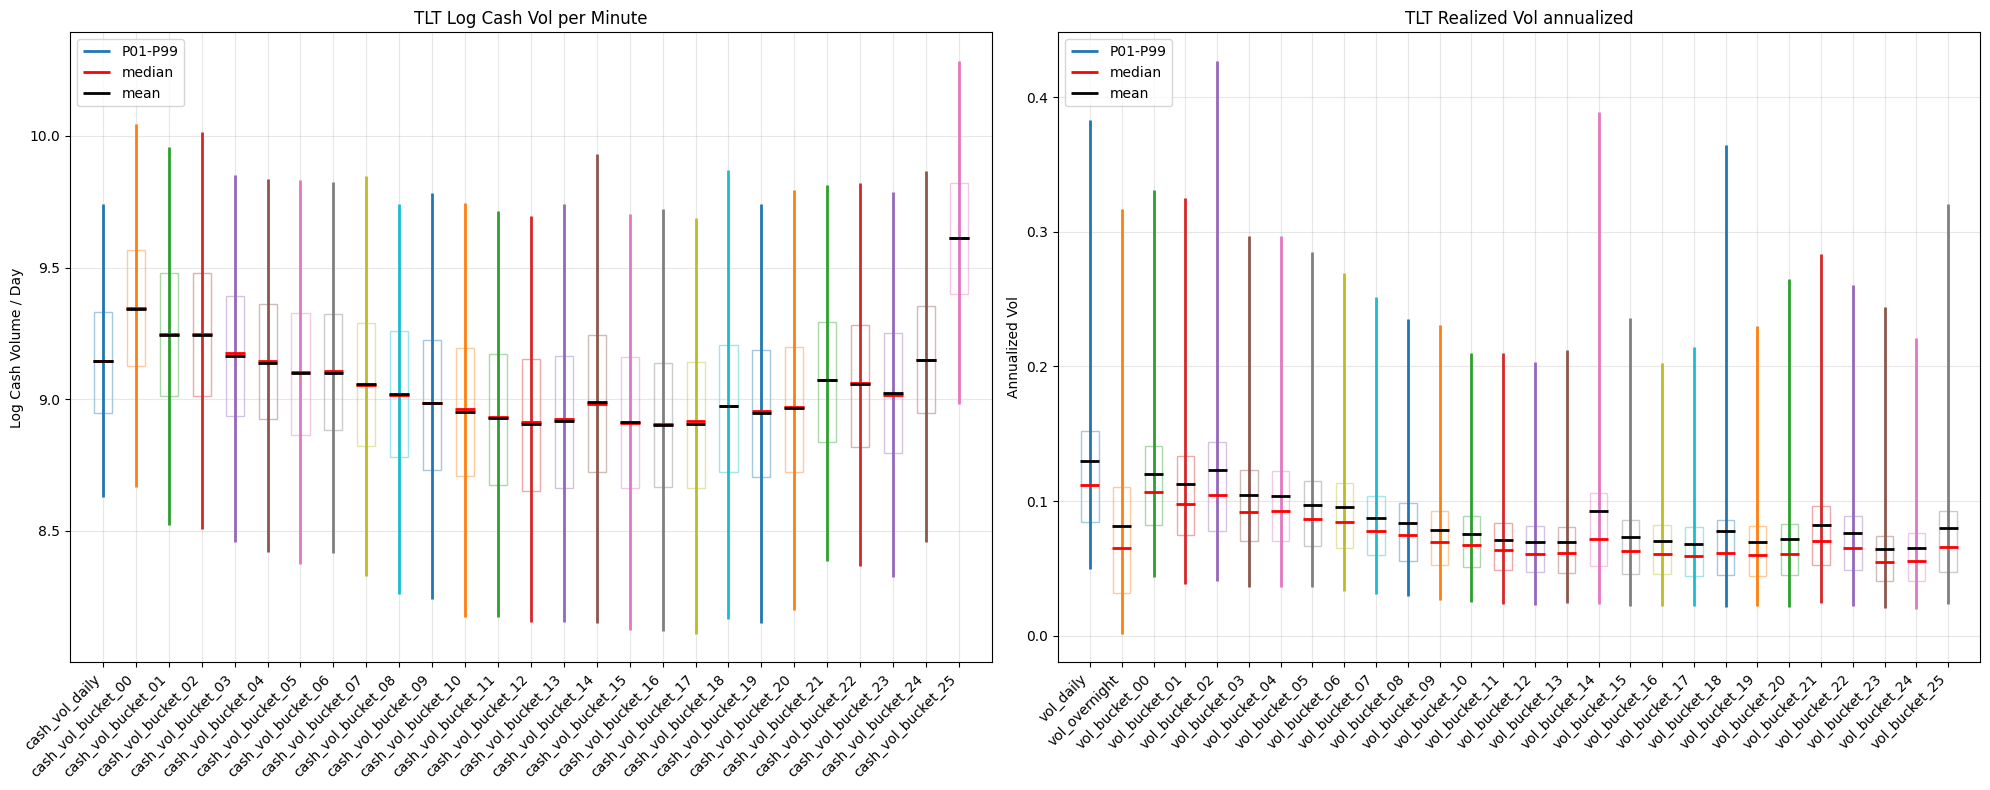

In [4]:
"""
Visualization
"""
from cdxcore.dynaplot import colors_tableau, figure
from cdxcore.pretty import PrettyObject
from matplotlib.patches import Rectangle
from prettytable import PrettyTable


def get_stats(data):
    assert len(data.shape) == 2

    stats = PrettyObject()
    stats.min_ = np.min(data, axis=0)
    stats.max_ = np.max(data, axis=0)
    (
        stats.p01,
        stats.p25,
        stats.p50,
        stats.p75,
        stats.p99,
    ) = np.quantile(data, (0.01, 0.25, 0.5, 0.75, 0.99), axis=0)
    stats.mean = np.mean(data, axis=0)
    stats.std = np.std(data, axis=0)
    return stats


def print_stats(stats, columns, what):
    tbl = PrettyTable()

    tbl.field_names = [""] + [f if f[-1:] != "_" else f[:-1] for f in stats]

    for ic, c in enumerate(columns):
        row = [c]
        for v in stats.values():
            row += [f"{v[ic]:.4g}"]
        tbl.add_row(row)

    display(Markdown("### " + what))
    display(tbl)


def plot_stats(ax, stats, columns, ylabel):

    assert stats.min_.shape == (len(columns),), ("Shape error", stats.min_.shape, len(columns))
    colors = colors_tableau()

    for ic, c in enumerate(columns):
        color = next(colors)

        # ax.vlines( ic, stats.min_[ic], stats.max_[ic], linewidth=1, color=color)
        ax.vlines(
            ic,
            stats.p01[ic],
            stats.p99[ic],
            linewidth=2,
            color=color,
            label="P01-P99" if ic == 0 else None,
        )

        # IQR box (p25-p75) as a thicker rectangle
        box_width = 0.55
        lo = stats.p25[ic]
        hi = stats.p75[ic]
        ax.add_patch(
            Rectangle(
                (ic - box_width / 2, lo),
                box_width,
                hi - lo,
                fill=False,
                linewidth=1,
                color=color,
                alpha=0.4,
            )
        )

        # mean and median ticks
        tick_halfwidth = 0.30
        xi = stats.p50[ic]
        ax.hlines(
            xi,
            ic - tick_halfwidth,
            ic + tick_halfwidth,
            linewidth=2,
            label="median" if ic == 0 else None,
            color="red",
        )
        xi = stats.mean[ic]
        ax.hlines(
            xi,
            ic - tick_halfwidth,
            ic + tick_halfwidth,
            linewidth=2,
            label="mean" if ic == 0 else None,
            color="black",
        )

    #    ax.set_xlabel(xlabel)
    ax.set_xlim(-1, len(columns))
    ax.set_xticks(np.arange(len(columns)))
    ax.set_xticklabels(columns, rotation=45, ha="right")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")


def plot(ticker, daily_wide):
    ticker_wide = daily_wide.filter(pl.col("ticker") == ticker).drop("ticker")

    volume_cols = ["cash_vol_daily"] + sorted(
        [c for c in ticker_wide.columns if c.startswith("cash_vol_bucket")]
    )
    rv_cols = ["vol_daily", "vol_overnight"] + sorted(
        [c for c in ticker_wide.columns if c.startswith("vol_bucket")]
    )

    volume = get_stats(ticker_wide.select(volume_cols).to_numpy())
    rvol = get_stats(ticker_wide.select(rv_cols).to_numpy())

    print_stats(
        volume,
        volume_cols,
        "volume: each bucket cash_vol is scaled to daily cash volume; daily_cash_vol is the daily cash volume",
    )
    print_stats(rvol, rv_cols, "realized vol, annualized")

    with figure(None, row_size=8, col_size=10, columns=None) as fig:
        axV, axVol = fig.add_subplots(
            f"{ticker} Log Cash Vol per Minute", f"{ticker} Realized Vol annualized"
        )

        plot_stats(axV, volume, volume_cols, "Log Cash Volume / Day")
        plot_stats(axVol, rvol, rv_cols, "Annualized Vol")


def plot_all(df_daily):
    tickers = sorted(df_daily["ticker"].unique())
    for ticker in tickers:
        display(Markdown(f"## {ticker}\n\n---"))
        plot(ticker, df_daily)


plot_all(df_daily)